# Hybrid network IDS: XGBoost + Benign-only autoencoder

CIC-IDS2017, flow features. A supervised classifier handles known attacks; an autoencoder trained only on
normal traffic re-checks every flow the classifier calls Benign. The question is how much the second
stage recovers when an attack family was never seen in training (zero-day).

All choices (weights, thresholds, ensemble) are made on the validation set; the test set is used once,
in the last section.

## Setup and raw dataset

Downloads the raw CIC-IDS2017 mirror from Kaggle. The raw data is only used for the EDA in section 1;
from section 2 on, the notebook works on the cleaned split in `../data/` (regenerated here if missing).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub
import os
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import torch
import torch.nn as nn

path = kagglehub.dataset_download("dhoogla/cicids2017")
print("Path to dataset files:", path)

Path to dataset files: ~/.cache/kagglehub/datasets/dhoogla/cicids2017/versions/3


In [2]:
fd = os.listdir(path)
print("Path to dataset files:" , fd)

Path to dataset files: ['Bruteforce-Tuesday-no-metadata.parquet', 'Infiltration-Thursday-no-metadata.parquet', 'DDoS-Friday-no-metadata.parquet', 'Benign-Monday-no-metadata.parquet', 'Botnet-Friday-no-metadata.parquet', 'DoS-Wednesday-no-metadata.parquet', 'WebAttacks-Thursday-no-metadata.parquet', 'Portscan-Friday-no-metadata.parquet']


In [3]:
df = pd.read_parquet(os.path.join(path,"Benign-Monday-no-metadata.parquet"))
print(df.shape)

(458831, 78)


In [4]:
fd = os.listdir(path)
print(fd)

df_all = []
for e in fd:
    df_all.append(pd.read_parquet(os.path.join(path,e)))

dataset = pd.concat(df_all)

print(dataset.head(1), dataset.shape)

# share of each class
print(dataset["Label"].value_counts(normalize=True))

['Bruteforce-Tuesday-no-metadata.parquet', 'Infiltration-Thursday-no-metadata.parquet', 'DDoS-Friday-no-metadata.parquet', 'Benign-Monday-no-metadata.parquet', 'Botnet-Friday-no-metadata.parquet', 'DoS-Wednesday-no-metadata.parquet', 'WebAttacks-Thursday-no-metadata.parquet', 'Portscan-Friday-no-metadata.parquet']


   Protocol  Flow Duration  Total Fwd Packets  Total Backward Packets  \
0         6            640                  7                       4   

   Fwd Packets Length Total  Bwd Packets Length Total  Fwd Packet Length Max  \
0                       440                       358                    220   

   Fwd Packet Length Min  Fwd Packet Length Mean  Fwd Packet Length Std  ...  \
0                      0               62.857143             107.349007  ...   

   Fwd Seg Size Min  Active Mean  Active Std  Active Max  Active Min  \
0                20          0.0         0.0           0           0   

   Idle Mean  Idle Std  Idle Max  Idle Min   Label  
0        0.0       0.0         0         0  Benign  

[1 rows x 78 columns] (2313810, 78)
Label
Benign                        0.854572
DoS Hulk                      0.074702
DDoS                          0.055326
DoS GoldenEye                 0.004445
FTP-Patator                   0.002563
DoS slowloris                 0.002327
DoS

## 1. EDA: missing values, statistics, invalid values

Run on the raw data. It found two problems: labels with a corrupted character (`Web Attack � XSS`)
and rows with negative values in columns that cannot be negative. They lead to the cleaning rules in section 2.

In [5]:

print("NaN value in dataset: " , dataset.isnull().sum().sum())
print("inf value in dataset: " , np.isinf(dataset.select_dtypes(include=np.number)).sum().sum())

pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
dataset.describe()

NaN value in dataset:  0
inf value in dataset:  0


,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Fwd Packets Length Total,Bwd Packets Length Total,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Fwd Act Data Packets,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min
count,"2,313,810.00","2,313,810.00","2,313,810.00","2,313,810.00","2,313,810.00","2,313,810.00","2,313,810.00","2,313,810.00","2,313,810.00","2,313,810.00",...,"2,313,810.00","2,313,810.00","2,313,810.00","2,313,810.00","2,313,810.00","2,313,810.00","2,313,810.00","2,313,810.00","2,313,810.00","2,313,810.00"
mean,10.51,"18,075,748.27",11.08,12.55,666.40,"19,769.76",250.63,21.42,68.81,82.99,...,6.54,"-3,360.48","99,770.87","50,323.97","187,405.34","71,319.80","10,172,610.00","616,408.75","10,637,159.02","9,688,132.65"
std,5.42,"36,408,233.47",829.19,"1,103.18","11,050.09","2,503,141.35",785.51,63.34,202.30,307.88,...,703.93,"1,200,083.77","716,135.12","434,579.50","1,131,814.34","637,582.00","25,771,430.00","5,084,448.50","26,564,407.95","25,506,700.38"
min,0.00,-13.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,"-536,870,661.00",0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,6.00,476.00,2.00,1.00,37.00,26.00,20.00,0.00,8.67,0.00,...,0.00,20.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,6.00,"64,783.00",2.00,2.00,74.00,183.00,43.00,6.00,39.56,0.00,...,1.00,20.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
75%,17.00,"5,856,947.75",6.00,5.00,356.00,"2,306.00",274.00,39.00,54.00,84.99,...,3.00,32.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
max,17.00,"119,999,998.00","219,759.00","291,922.00","12,900,000.00","655,453,030.00","24,820.00","2,325.00","5,940.86","7,125.60",...,"213,557.00",138.00,"110,000,000.00","74,200,000.00","110,000,000.00","110,000,000.00","120,000,000.00","76,900,000.00","120,000,000.00","120,000,000.00"


In [6]:
# columns with at least one negative value
f_bool = (((dataset.select_dtypes(np.number) < 0).sum()).sort_values(ascending=False) > 0 )
colm_names = f_bool[f_bool].index
print(colm_names)

dirty_colm, dirty_rows= [] , []
# a single distinct negative value is a sentinel (e.g. -1 in Init Win Bytes); more than one is invalid data
for e in colm_names:
    check = dataset[dataset[e] < 0][e].value_counts()
    if len(check) > 1:
        print(e, len(check), "distinct values")
        dirty_colm.append(e)

print(dirty_colm)

dirty_rows = (dataset[dirty_colm] < 0).any(axis=1)
print(dirty_rows.sum())





Index(['Init Bwd Win Bytes', 'Init Fwd Win Bytes', 'Flow IAT Min',
       'Flow IAT Mean', 'Flow Duration', 'Flow Packets/s', 'Flow IAT Max',
       'Flow Bytes/s', 'Fwd Header Length', 'Fwd Seg Size Min',
       'Bwd Header Length', 'Fwd IAT Min'],
      dtype='str')


Flow IAT Min 12 distinct values
Flow IAT Mean 5 distinct values
Flow Duration 5 distinct values
Flow Packets/s 5 distinct values
Flow IAT Max 5 distinct values
Flow Bytes/s 9 distinct values
Fwd Header Length 27 distinct values
Fwd Seg Size Min 4 distinct values
Bwd Header Length 17 distinct values
Fwd IAT Min 3 distinct values
['Flow IAT Min', 'Flow IAT Mean', 'Flow Duration', 'Flow Packets/s', 'Flow IAT Max', 'Flow Bytes/s', 'Fwd Header Length', 'Fwd Seg Size Min', 'Bwd Header Length', 'Fwd IAT Min']
2843


## 2. Cleaning and train/validation/test split

Corrupted label character replaced with `-`; rows with negatives in the invalid columns (`dirty_colm`, 2,843 rows)
removed (2,143 corrected labels, 2,843 removed rows). Stratified 60/20/20 split, seed 42. Saved once to `../data/` and reloaded from there.

In [7]:
# Regenerates the cleaned parquet files if missing (same logic as data/regenerate_split.py).
# File order is fixed: os.listdir order differs between systems and would change the split.
cartella = "../data"
if not os.path.exists(f"{cartella}/train.parquet"):
    ordine_file = ["Infiltration-Thursday", "Botnet-Friday", "Benign-Monday", "DDoS-Friday",
                   "WebAttacks-Thursday", "Bruteforce-Tuesday", "Portscan-Friday", "DoS-Wednesday"]
    grezzo = pd.concat([pd.read_parquet(os.path.join(path, f"{n}-no-metadata.parquet")) for n in ordine_file])
    grezzo["Label"] = grezzo["Label"].str.replace("�", "-", regex=False)
    grezzo = grezzo[~(grezzo[dirty_colm] < 0).any(axis=1)]
    train, temp = train_test_split(grezzo, train_size=0.6, stratify=grezzo["Label"], random_state=42)
    val, test = train_test_split(temp, test_size=0.5, stratify=temp["Label"], random_state=42)
    os.makedirs(cartella, exist_ok=True)
    for nome, parte in [("train", train), ("val", val), ("test", test)]:
        parte.to_parquet(f"{cartella}/{nome}.parquet")

train = pd.read_parquet(f"{cartella}/train.parquet")
val = pd.read_parquet(f"{cartella}/val.parquet")
test = pd.read_parquet(f"{cartella}/test.parquet")
print(train.shape, val.shape, test.shape)


(1386580, 78) (462193, 78) (462194, 78)


In [8]:
X_train = train.drop("Label", axis=1)
y_train = train["Label"]

X_val= val.drop("Label", axis=1)
y_val = val["Label"]


X_test= test.drop("Label", axis=1)
y_test = test["Label"]

## 3. Random Forest baseline

Default class weights first.

In [9]:
# baseline: max_depth=15 keeps the forest small; no class weights
rf = RandomForestClassifier(random_state=42, max_depth=15,n_jobs=-1)
rf.fit(X_train, y_train)
preds = rf.predict(X_val)
print(classification_report(y_val, preds), "\n")


.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


                            precision    recall  f1-score   support

                    Benign       1.00      1.00      1.00    394933
                       Bot       1.00      0.48      0.64       288
                      DDoS       1.00      1.00      1.00     25599
             DoS GoldenEye       1.00      0.98      0.99      2056
                  DoS Hulk       1.00      0.99      1.00     34537
          DoS Slowhttptest       0.94      0.99      0.96      1045
             DoS slowloris       1.00      0.99      0.99      1077
               FTP-Patator       1.00      0.99      1.00      1185
                Heartbleed       1.00      1.00      1.00         2
              Infiltration       1.00      0.43      0.60         7
                  PortScan       0.96      0.88      0.92       391
               SSH-Patator       1.00      0.91      0.95       644
  Web Attack - Brute Force       0.68      0.84      0.75       294
Web Attack - Sql Injection       0.00      0.00

.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


'                            precision    recall  f1-score   support\n\n                    Benign       1.00      1.00      1.00    394933\n                       Bot       1.00      0.48      0.64       288\n                      DDoS       1.00      1.00      1.00     25599\n             DoS GoldenEye       1.00      0.98      0.99      2056\n                  DoS Hulk       1.00      0.99      1.00     34537\n          DoS Slowhttptest       0.94      0.99      0.96      1045\n             DoS slowloris       1.00      0.99      0.99      1077\n               FTP-Patator       1.00      0.99      1.00      1185\n                Heartbleed       1.00      1.00      1.00         2\n              Infiltration       1.00      0.43      0.60         7\n                  PortScan       0.96      0.88      0.92       391\n               SSH-Patator       1.00      0.91      0.95       644\n  Web Attack - Brute Force       0.68      0.84      0.75       294\nWeb Attack - Sql Injection     

<Axes: >

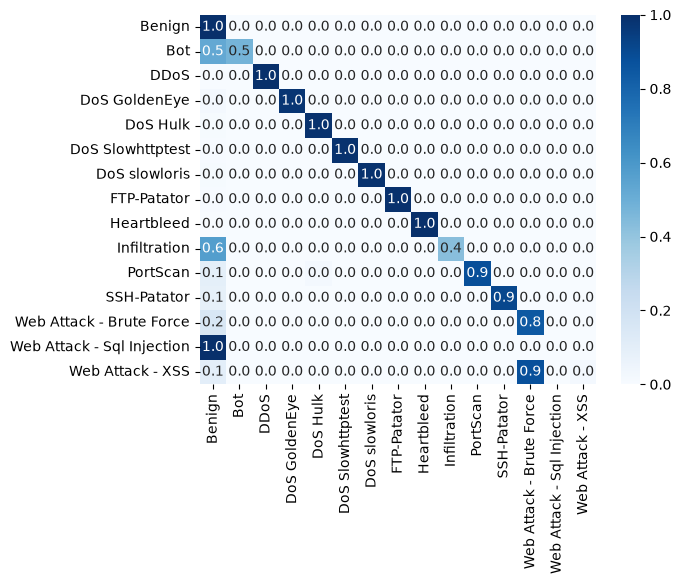

In [10]:
# row-normalised confusion matrix: each row is a true class, diagonal = recall
cm = confusion_matrix(y_val, preds, normalize='true')
sns.heatmap(cm, annot=True, fmt=".1f", xticklabels=rf.classes_, yticklabels=rf.classes_, cmap='Blues')


Same model with `class_weight='balanced'`, to see whether rare classes improve.

                            precision    recall  f1-score   support

                    Benign       1.00      0.98      0.99    394933
                       Bot       0.06      0.99      0.11       288
                      DDoS       1.00      1.00      1.00     25599
             DoS GoldenEye       0.96      1.00      0.98      2056
                  DoS Hulk       0.99      0.99      0.99     34537
          DoS Slowhttptest       0.93      0.99      0.96      1045
             DoS slowloris       0.99      0.99      0.99      1077
               FTP-Patator       0.99      1.00      0.99      1185
                Heartbleed       1.00      1.00      1.00         2
              Infiltration       1.00      1.00      1.00         7
                  PortScan       0.79      0.98      0.87       391
               SSH-Patator       0.74      0.98      0.84       644
  Web Attack - Brute Force       0.21      0.47      0.29       294
Web Attack - Sql Injection       0.01      0.75

<Axes: >

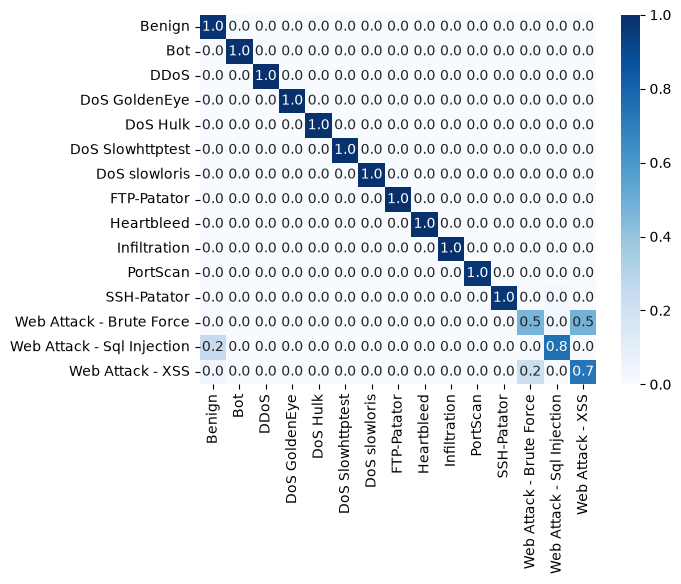

In [11]:
# 'balanced': weight inversely proportional to class frequency
rf = RandomForestClassifier(random_state=42, max_depth=15,n_jobs=-1,class_weight='balanced')
rf.fit(X_train, y_train)
preds = rf.predict(X_val)
print(classification_report(y_val, preds), "\n")
cm = confusion_matrix(y_val, preds, normalize='true')
sns.heatmap(cm, annot=True, fmt=".1f", xticklabels=rf.classes_, yticklabels=rf.classes_, cmap='Blues')


Manual class weights by severity: rare and more dangerous attacks weigh more.

                            precision    recall  f1-score   support

                    Benign       1.00      1.00      1.00    394933
                       Bot       0.61      0.84      0.71       288
                      DDoS       1.00      1.00      1.00     25599
             DoS GoldenEye       0.99      0.99      0.99      2056
                  DoS Hulk       0.99      1.00      0.99     34537
          DoS Slowhttptest       0.94      0.99      0.96      1045
             DoS slowloris       1.00      0.99      0.99      1077
               FTP-Patator       1.00      1.00      1.00      1185
                Heartbleed       1.00      1.00      1.00         2
              Infiltration       1.00      0.86      0.92         7
                  PortScan       0.93      0.96      0.95       391
               SSH-Patator       1.00      0.94      0.97       644
  Web Attack - Brute Force       0.68      0.90      0.78       294
Web Attack - Sql Injection       1.00      0.25

<Axes: >

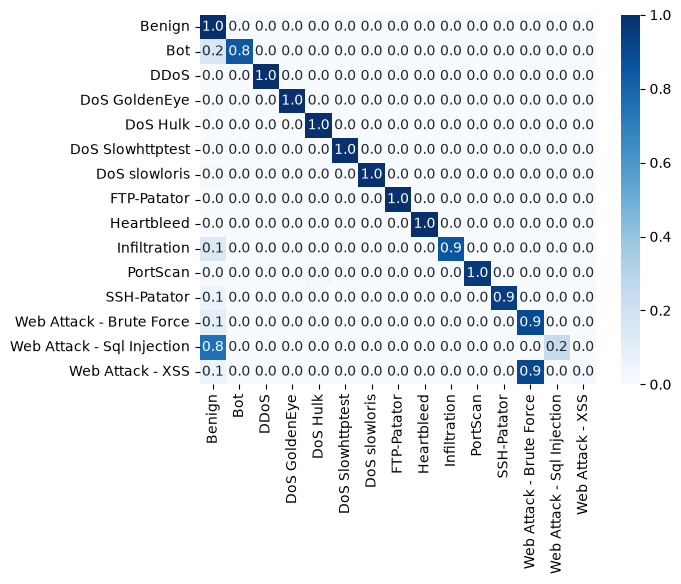

In [12]:
# manual weights: the rarer and more dangerous the attack, the higher the weight
weights = {
    "Benign": 1,
    "Heartbleed": 50,
    "Web Attack - Sql Injection": 45,
    "Infiltration": 40,
    "Web Attack - XSS": 35,
    "Web Attack - Brute Force": 30,
    "FTP-Patator": 28,
    "SSH-Patator": 26,
    "Bot": 25,
    "PortScan": 22,
    "DoS slowloris": 20,
    "DoS Slowhttptest": 20,
    "DoS GoldenEye": 18,
    "DDoS": 15,
    "DoS Hulk": 12,
    }

# class_weight accepts a dict {label: weight}
rf_custom = RandomForestClassifier(class_weight=weights,random_state=42,max_depth=15,n_jobs=-1)
rf_custom.fit(X_train,y_train)
preds = rf_custom.predict(X_val)
print(classification_report(y_val,preds))
cm = confusion_matrix(y_val, preds, normalize='true')
sns.heatmap(cm, annot=True, fmt=".1f", xticklabels=rf_custom.classes_, yticklabels=rf_custom.classes_, cmap='Blues')

## 4. XGBoost baseline

.venv/lib/python3.11/site-packages/xgboost/core.py:751: UserWarning: [13:06:23] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


                            precision    recall  f1-score   support

                    Benign       1.00      1.00      1.00    394933
                       Bot       0.50      0.69      0.58       288
                      DDoS       1.00      0.99      0.99     25599
             DoS GoldenEye       0.91      0.87      0.89      2056
                  DoS Hulk       0.99      0.99      0.99     34537
          DoS Slowhttptest       0.76      0.80      0.78      1045
             DoS slowloris       0.63      0.61      0.62      1077
               FTP-Patator       0.91      0.94      0.92      1185
                Heartbleed       0.00      0.00      0.00         2
              Infiltration       0.03      0.14      0.04         7
                  PortScan       0.73      0.73      0.73       391
               SSH-Patator       0.86      0.91      0.89       644
  Web Attack - Brute Force       0.55      0.52      0.54       294
Web Attack - Sql Injection       0.00      0.00

<Axes: >

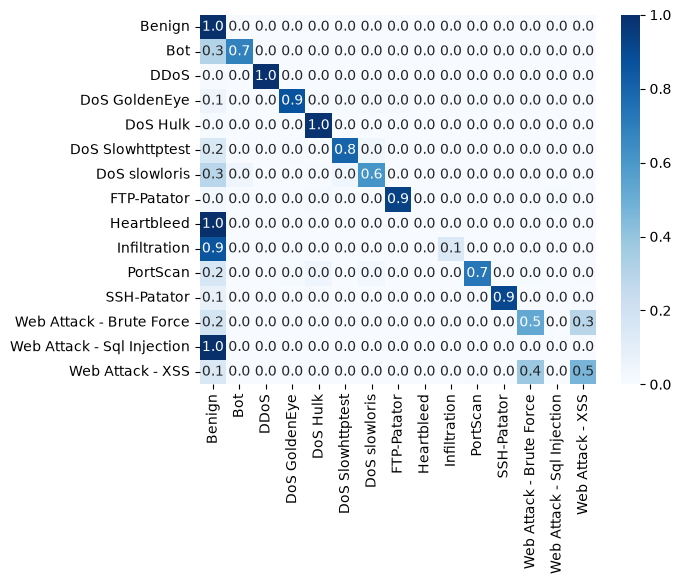

In [13]:
import xgboost as xgb
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder

# XGBoost needs integer labels; le.classes_ keeps the mapping back to names
le = LabelEncoder()
y_train_enc =le.fit_transform(y_train)
y_val_enc = le.transform(y_val)

# device="cuda": training on GPU (the notebook needs a CUDA GPU for XGBoost)
xgb_model_default = XGBClassifier(random_state=42, n_estimators=100, max_depth=6, device="cuda")
xgb_model_default.fit(X_train, y_train_enc)
preds_default = xgb_model_default.predict(X_val)
cr_xgb_default = classification_report(y_val_enc, preds_default, target_names=le.classes_)
print(cr_xgb_default)
# row-normalised confusion matrix, as for the Random Forest
cm_xgb_default = confusion_matrix(y_val_enc, preds_default, normalize='true')
sns.heatmap(cm_xgb_default, annot=True, fmt=".1f", xticklabels=le.classes_, yticklabels=le.classes_, cmap='Blues')

### XGBoost with severity-based sample weights

                            precision    recall  f1-score   support

                    Benign       1.00      1.00      1.00    394933
                       Bot       0.62      0.90      0.73       288
                      DDoS       1.00      1.00      1.00     25599
             DoS GoldenEye       1.00      1.00      1.00      2056
                  DoS Hulk       1.00      1.00      1.00     34537
          DoS Slowhttptest       0.93      0.99      0.96      1045
             DoS slowloris       0.99      0.99      0.99      1077
               FTP-Patator       1.00      0.99      1.00      1185
                Heartbleed       1.00      1.00      1.00         2
              Infiltration       1.00      0.71      0.83         7
                  PortScan       0.93      0.96      0.94       391
               SSH-Patator       1.00      1.00      1.00       644
  Web Attack - Brute Force       0.79      0.63      0.70       294
Web Attack - Sql Injection       0.67      0.50

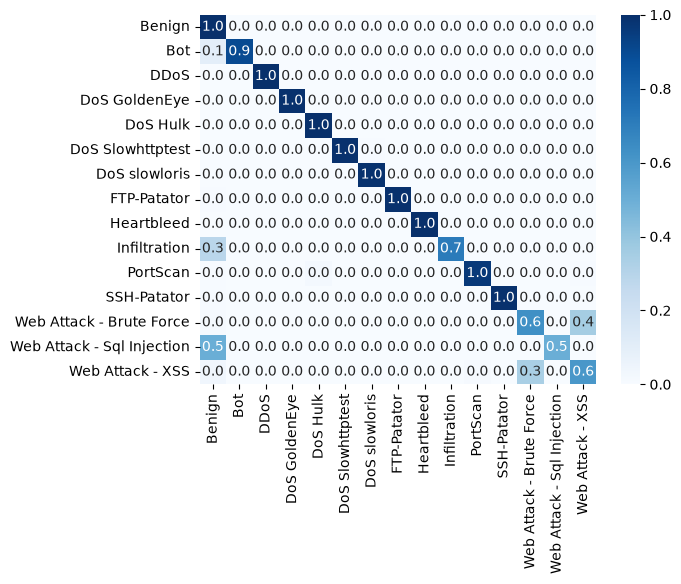

In [14]:
# per-sample weights: XGBClassifier has no class_weight parameter
weights = {
    "Benign": 0.1,
    "Heartbleed": 0.7,
    "Web Attack - Sql Injection": 0.91,
    "Infiltration": 0.93,
    "Web Attack - XSS": 0.6,
    "Web Attack - Brute Force": 0.3,
    "FTP-Patator": 0.28,
    "SSH-Patator": 0.26,
    "Bot": 0.27,
    "PortScan": 0.22,
    "DoS slowloris": 0.20,
    "DoS Slowhttptest": 0.20,
    "DoS GoldenEye": 0.18,
    "DDoS": 0.15,
    "DoS Hulk": 0.12,
    }

# small weight on Benign (the majority class), larger on the rare attacks
sample_weights = y_train.map(weights)
xgb_model = XGBClassifier(random_state=42, n_estimators=100, max_depth=6, device="cuda")
xgb_model.fit(X_train, y_train_enc,sample_weight=sample_weights)
preds = xgb_model.predict(X_val)
cr_xgb = classification_report(y_val_enc, preds, target_names=le.classes_)
print(cr_xgb)
cm_xgb = confusion_matrix(y_val_enc, preds, normalize='true')
sns.heatmap(cm_xgb, annot=True, fmt=".1f", xticklabels=le.classes_, yticklabels=le.classes_, cmap='Blues')
print(sample_weights.isna().sum())   # every label must have a weight

## 5. Autoencoder trained on Benign only

MLP 77 → 32 → 16 → 32 → 77, ReLU, dropout 0.1 in the encoder, MSE loss. Inputs standardised on the
Benign training flows. A high reconstruction error means the flow does not look like normal traffic.

In [15]:
mask_bening = y_train == "Benign"
X_train_bening = X_train[mask_bening]
print(mask_bening.shape, X_train_bening.shape)


(1386580,) (1184801, 77)


In [16]:
class Autoencoder(nn.Module):
  def __init__(self, p_dropout=0.1):
    super().__init__()
    self.encoder = nn.Sequential(
        nn.Linear(77,32),
        nn.ReLU(),
        nn.Dropout(p_dropout),
        nn.Linear(32,16),
        nn.ReLU(),
        nn.Dropout(p_dropout),
    )

    self.decoder = nn.Sequential(
        nn.Linear(16,32),
        nn.ReLU(),
        nn.Linear(32,77)
    )

  def forward(self, x):
    encoded = self.encoder(x)
    decoded = self.decoder(encoded)
    return decoded


if torch.cuda.is_available():
  device = "cuda"
else:
  device = "cpu"
print(f"Using {device} device")

# scaler fitted on Benign only: the autoencoder must never see attack statistics
scaler = StandardScaler()
X_train_bening_scaled = scaler.fit_transform(X_train_bening)
X_val_scaled = scaler.transform(X_val)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32).to(device)

X_train_tensor = torch.tensor(X_train_bening_scaled, dtype=torch.float32).to(device)
torch.manual_seed(42)
model = Autoencoder().to(device)
criterion = nn.MSELoss()


Using cuda device


Full-batch training in two stages (lr 0.01, then 0.001 on the same model). Each stage stops on a plateau:
the mean loss of the last 50 epochs is compared with the previous 50, so a single noisy epoch (dropout)
does not stop training early.

In [17]:
def allena_fino_a_plateau(model, optimizer, X_train_tensor, criterion,
                           finestra=50, soglia_rel=0.002, max_epochs=3000, log_ogni=50):
    loss_storico = []

    for epoch in range(max_epochs):
        optimizer.zero_grad()
        output = model(X_train_tensor)
        loss = criterion(output, X_train_tensor)
        loss.backward()
        optimizer.step()
        loss_storico.append(loss.item())

        # non-overlapping windows: two overlapping means always differ very little
        # and the criterion would fire immediately
        if len(loss_storico) >= 2 * finestra:
            media_prec = np.mean(loss_storico[-2 * finestra:-finestra])
            media_attuale = np.mean(loss_storico[-finestra:])
            miglioramento_rel = (media_prec - media_attuale) / media_prec
            if miglioramento_rel < soglia_rel:
                print(f"Plateau at epoch {epoch} (mean of last {finestra}: {media_attuale:.4f}, "
                      f"improvement {miglioramento_rel:.2%})")
                break

        if epoch % log_ogni == 0:
            print(f"epoch {epoch}: loss={loss.item():.4f}")
    else:
        print(f"Reached max_epochs={max_epochs}, final loss {loss_storico[-1]:.4f}")

    return loss_storico


print("--- Stage 1: lr=0.01 (fast convergence to a coarse plateau) ---")
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
storico_fase1 = allena_fino_a_plateau(model, optimizer, X_train_tensor, criterion)

print("\n--- Stage 2: lr=0.001 (fine-tuning the same model) ---")
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
storico_fase2 = allena_fino_a_plateau(model, optimizer, X_train_tensor, criterion)


--- Stage 1: lr=0.01 (fast convergence to a coarse plateau) ---


epoch 0: loss=0.9071


epoch 50: loss=0.2678


epoch 100: loss=0.1809


epoch 150: loss=0.1507


...

epoch 450: loss=0.1135


Plateau at epoch 474 (mean of last 50: 0.1181, improvement 0.02%)

--- Stage 2: lr=0.001 (fine-tuning the same model) ---
epoch 0: loss=0.1152


epoch 50: loss=0.1076


epoch 100: loss=0.1085


Plateau at epoch 103 (mean of last 50: 0.1119, improvement 0.18%)


### Validation: reconstruction error, Benign vs attacks

The threshold is a percentile of the Benign error: the 95th percentile flags 5% of normal traffic by construction.

In [18]:
model.eval()

with torch.no_grad():
  output = model(X_val_tensor).to(device)
  loss = ((output - X_val_tensor)**2).mean(dim=1)   # per-flow MSE = anomaly score

errori = loss.cpu().numpy()
mask_bening = y_val == 'Benign'
errori_benign = errori[mask_bening]
errori_attacco = errori[~mask_bening]
print("\nbenign: ",errori_benign.mean(), errori_benign.max(), "\nattack: ", errori_attacco.mean(), errori_attacco.max())

print("\n95th percentile threshold")

treshold = np.percentile(errori_benign,95)
treshold_99 = np.percentile(errori_benign,99)

predictions = errori > treshold
print(errori[predictions].shape)
mask_attacco = y_val != 'Benign'



benign:  0.074113 8139.5796 
attack:  1.7607831 455.2971

95th percentile threshold
(68973,)


              precision    recall  f1-score   support

      Benign       0.95      0.95      0.95    394933
      Attack       0.71      0.73      0.72     67260

    accuracy                           0.92    462193
   macro avg       0.83      0.84      0.84    462193
weighted avg       0.92      0.92      0.92    462193



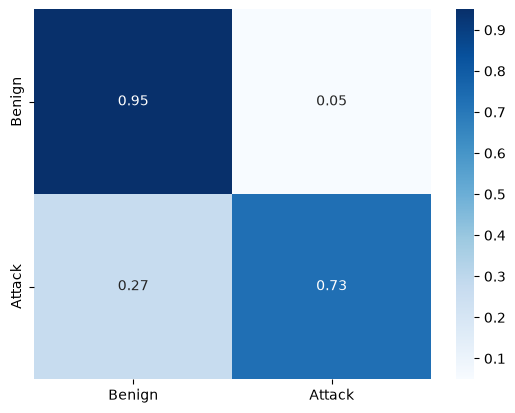

In [19]:
cm_mlp = confusion_matrix(mask_attacco, predictions, normalize='true', labels=[False, True])
sns.heatmap(cm_mlp, annot=True, fmt=".2f", xticklabels=['Benign','Attack'], yticklabels=['Benign','Attack'], cmap='Blues')
cr_mlp = classification_report(mask_attacco, predictions, target_names=['Benign','Attack'])
print(cr_mlp)


### Targeted test: how many attacks missed by XGBoost does the autoencoder recover?

The cell below uses the **95th** Benign percentile (threshold `treshold`), hence 98.62% after the autoencoder.
The rest of the notebook uses the **99th** percentile (98.37% with one autoencoder, 98.51% with the ensemble).

In [20]:
# false negatives: XGBoost predicted Benign (class 0) but the flow is an attack
totale_attacchi = (y_val_enc != 0).sum()

mask_xgb_mlp = (preds == 0) & (y_val_enc != 0)
err_xgb = errori[mask_xgb_mlp]
tot_err = (err_xgb > treshold).sum()
print("Weighted XGBoost - missed attacks:", err_xgb.shape[0], "| recovered by the AE:", tot_err)

mask_xgb_default = (preds_default == 0) & (y_val_enc != 0)
err_xgb_default = errori[mask_xgb_default]
tot_err_default = (err_xgb_default > treshold).sum()
print("Default XGBoost - missed attacks:", err_xgb_default.shape[0], "| recovered by the AE:", tot_err_default)

print(f"\nTotal attacks in validation: {totale_attacchi}\n")

recall_xgb_default = (totale_attacchi - err_xgb_default.shape[0]) / totale_attacchi
recall_xgb_default_mlp = (totale_attacchi - err_xgb_default.shape[0] + tot_err_default) / totale_attacchi
print(f"recall XGBoost default:      {recall_xgb_default:.2%}")
print(f"recall XGBoost default + AE: {recall_xgb_default_mlp:.2%}")

recall_xgb = (totale_attacchi - err_xgb.shape[0]) / totale_attacchi
recall_xgb_mlp = (totale_attacchi - err_xgb.shape[0] + tot_err) / totale_attacchi
print(f"\nrecall XGBoost weighted:      {recall_xgb:.2%}")
print(f"recall XGBoost weighted + AE: {recall_xgb_mlp:.2%}")


Weighted XGBoost - missed attacks: 90 | recovered by the AE: 7
Default XGBoost - missed attacks: 1304 | recovered by the AE: 374

Total attacks in validation: 67260

recall XGBoost default:      98.06%
recall XGBoost default + AE: 98.62%

recall XGBoost weighted:      99.87%
recall XGBoost weighted + AE: 99.88%


In [21]:
# 95th vs 99th percentile threshold
tot_err_99 = (err_xgb > treshold_99).sum()
tot_err_default_99 = (err_xgb_default > treshold_99).sum()

print(f"Threshold 95%: {treshold:.4f}  |  Threshold 99%: {treshold_99:.4f}\n")
print(f"Recovered (XGBoost weighted) — 95%: {tot_err}/{err_xgb.shape[0]}  |  99%: {tot_err_99}/{err_xgb.shape[0]}")
print(f"Recovered (XGBoost default)  — 95%: {tot_err_default}/{err_xgb_default.shape[0]}  |  99%: {tot_err_default_99}/{err_xgb_default.shape[0]}")


Threshold 95%: 0.1911  |  Threshold 99%: 0.6377

Recovered (XGBoost weighted) — 95%: 7/90  |  99%: 3/90
Recovered (XGBoost default)  — 95%: 374/1304  |  99%: 209/1304


### Missed attacks with and without the autoencoder

/tmp/ipykernel_29710/1808596402.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=persi_confronto, x='scenario', y='missed', ax=axes[0], palette=['tab:blue', 'gold'])
/tmp/ipykernel_29710/1808596402.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=persi_confronto_w, x='scenario', y='missed', ax=axes[1], palette=['tab:blue', 'gold'])


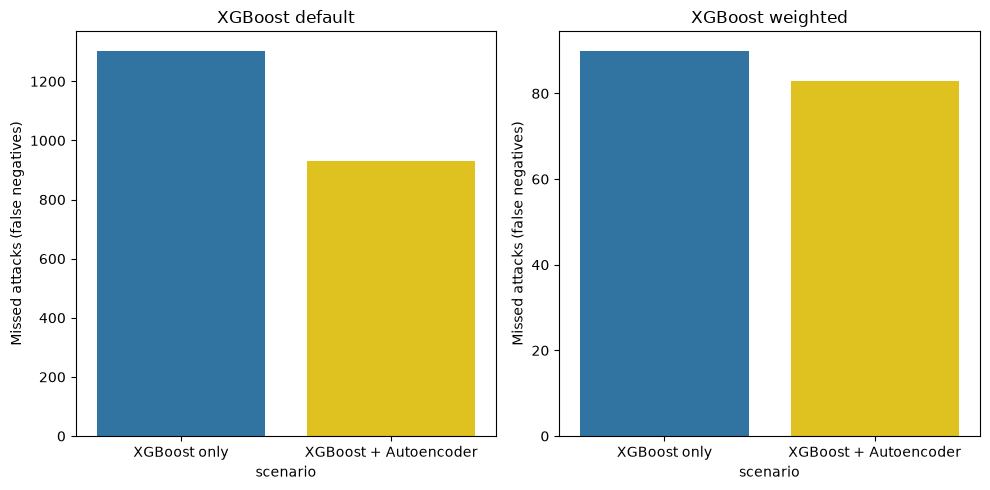

In [22]:
persi_prima = err_xgb_default.shape[0]
persi_dopo = persi_prima - tot_err_default

persi_confronto = pd.DataFrame({
    'scenario': ['XGBoost only', 'XGBoost + Autoencoder'],
    'missed': [persi_prima, persi_dopo]
})

persi_prima_w = err_xgb.shape[0]
persi_dopo_w = persi_prima_w - tot_err

persi_confronto_w = pd.DataFrame({
    'scenario': ['XGBoost only', 'XGBoost + Autoencoder'],
    'missed': [persi_prima_w, persi_dopo_w]
})

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

sns.barplot(data=persi_confronto, x='scenario', y='missed', ax=axes[0], palette=['tab:blue', 'gold'])
axes[0].set_title('XGBoost default')
axes[0].set_ylabel('Missed attacks (false negatives)')

sns.barplot(data=persi_confronto_w, x='scenario', y='missed', ax=axes[1], palette=['tab:blue', 'gold'])
axes[1].set_title('XGBoost weighted')
axes[1].set_ylabel('Missed attacks (false negatives)')

plt.tight_layout()

## 6. Hybrid pipeline as a function

Generalises the manual comparison above. Besides the recall gain it reports the cost of the second stage
(false positives added on Benign traffic) and a per-class breakdown.

In [23]:
def pipeline_ibrida(preds_clf, y_true_enc, y_true_label, errori_ae, soglia_ae, classe_benign=0):
    """
    Classifier + autoencoder: a Benign prediction is kept only if the reconstruction error
    stays below the threshold. Returns recall and FPR (classifier only, added by the AE, total)
    and a per-class breakdown.
    """
    y_true_attacco = y_true_enc != classe_benign
    pred_clf_benign = preds_clf == classe_benign

    fn_clf = pred_clf_benign & y_true_attacco          # attacks missed by the classifier
    flag_ae = errori_ae > soglia_ae
    fn_recuperati = fn_clf & flag_ae                   # missed by the classifier, caught by the AE
    fn_dopo = fn_clf & ~flag_ae                         # still missed

    # cost: classifier was right (true Benign) but the AE raises an alert anyway
    fp_aggiunti = pred_clf_benign & ~y_true_attacco & flag_ae
    fp_clf = ~pred_clf_benign & ~y_true_attacco

    totale_attacchi = y_true_attacco.sum()
    totale_benign = (~y_true_attacco).sum()

    # breakdown on the original labels, not the encoded ones
    classi_attacco = y_true_label[y_true_attacco].unique()
    breakdown = []
    for classe in classi_attacco:
        mask_classe = y_true_label == classe
        fn_classe = fn_clf & mask_classe
        rec_classe = fn_recuperati & mask_classe
        breakdown.append({
            "class": classe,
            "fn_before": int(fn_classe.sum()),
            "fn_after": int((fn_classe & ~flag_ae).sum()),
            "recovered": int(rec_classe.sum()),
        })
    breakdown_df = pd.DataFrame(breakdown).sort_values("fn_before", ascending=False)

    return {
        "recall_solo_clf": (totale_attacchi - fn_clf.sum()) / totale_attacchi,
        "recall_ibrido": (totale_attacchi - fn_dopo.sum()) / totale_attacchi,
        "fn_recuperati": int(fn_recuperati.sum()),
        "fp_aggiunti": int(fp_aggiunti.sum()),
        "fpr_solo_clf": fp_clf.sum() / totale_benign,
        "fpr_aggiunto_ae": fp_aggiunti.sum() / totale_benign,
        "fpr_ibrido": (fp_clf.sum() + fp_aggiunti.sum()) / totale_benign,
        "breakdown_per_classe": breakdown_df,
    }


Both XGBoost variants, threshold at the 99th Benign percentile (about 1% extra false positives).

"Extra" false positives are only those added by the autoencoder; "total" also includes the XGBoost false alarms.

In [24]:
# positional index, aligned with the numpy arrays
y_val_reset = y_val.reset_index(drop=True)

r_default = pipeline_ibrida(preds_default, y_val_enc, y_val_reset, errori, treshold_99)
r_pesato = pipeline_ibrida(preds, y_val_enc, y_val_reset, errori, treshold_99)

for nome, r in [("XGBoost default", r_default), ("XGBoost weighted", r_pesato)]:
    print(f"\n--- {nome} ---")
    print(f"Recall: {r['recall_solo_clf']:.4f} -> {r['recall_ibrido']:.4f} "
          f"({r['fn_recuperati']} attacks recovered)")
    print(f"Extra FPR from the autoencoder: {r['fpr_aggiunto_ae']:.4%} "
          f"({r['fp_aggiunti']} extra false positives out of {int((y_val_enc==0).sum())} Benign)")
    print(f"Total FPR: {r['fpr_solo_clf']:.4%} (XGBoost only) -> {r['fpr_ibrido']:.4%} (pipeline)")



--- XGBoost default ---
Recall: 0.9806 -> 0.9837 (209 attacks recovered)
Extra FPR from the autoencoder: 0.9655% (3813 extra false positives out of 394933 Benign)
Total FPR: 0.3720% (XGBoost only) -> 1.3374% (pipeline)

--- XGBoost weighted ---
Recall: 0.9987 -> 0.9987 (3 attacks recovered)
Extra FPR from the autoencoder: 0.9999% (3949 extra false positives out of 394933 Benign)
Total FPR: 0.0869% (XGBoost only) -> 1.0868% (pipeline)


In [25]:
# where the autoencoder helps, per attack class (XGBoost default)
print(r_default["breakdown_per_classe"])


                         class  fn_before  fn_after  recovered
9                DoS slowloris        314       297         17
0                     DoS Hulk        292       277         15
5             DoS Slowhttptest        158        86         72
2                         DDoS        120        88         32
3                DoS GoldenEye        107        45         62
4                          Bot         89        83          6
7                     PortScan         62        62          0
8     Web Attack - Brute Force         53        53          0
1                  SSH-Patator         49        48          1
6                  FTP-Patator         29        29          0
10            Web Attack - XSS         19        18          1
12                Infiltration          6         5          1
11  Web Attack - Sql Injection          4         4          0
13                  Heartbleed          2         0          2


### Threshold sweep (recall vs FPR)

   percentile  threshold  recall  fpr
0       50.00       0.02    1.00 0.50
1       75.00       0.04    0.99 0.25
2       90.00       0.10    0.99 0.10
3       95.00       0.19    0.99 0.05
4       97.00       0.30    0.99 0.03
5       99.00       0.64    0.98 0.01
6       99.50       1.00    0.98 0.00
7       99.90       2.15    0.98 0.00


Text(0.5, 1.0, 'Autoencoder threshold trade-off — default XGBoost + autoencoder')

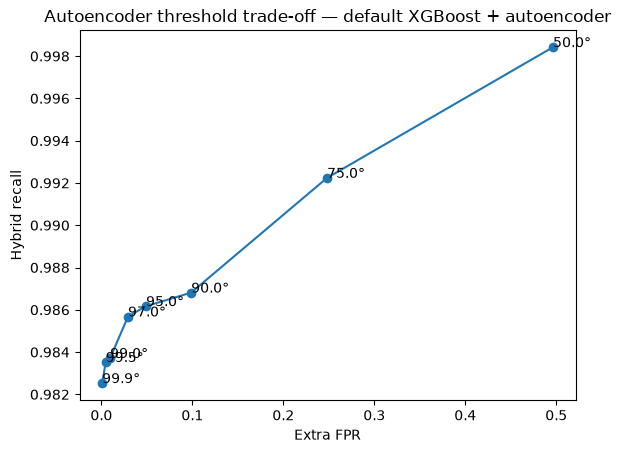

In [26]:
def curva_soglia(preds_clf, y_true_enc, y_true_label, errori_ae, percentili, classe_benign=0):
    risultati = []
    errori_benign_ref = errori_ae[y_true_enc == classe_benign]
    for p in percentili:
        soglia = np.percentile(errori_benign_ref, p)
        r = pipeline_ibrida(preds_clf, y_true_enc, y_true_label, errori_ae, soglia, classe_benign)
        risultati.append({"percentile": p, "threshold": soglia,
                           "recall": r["recall_ibrido"], "fpr": r["fpr_aggiunto_ae"]})
    return pd.DataFrame(risultati)

percentili = [50, 75, 90, 95, 97, 99, 99.5, 99.9]
curva = curva_soglia(preds_default, y_val_enc, y_val_reset, errori, percentili)
print(curva)

plt.plot(curva["fpr"], curva["recall"], marker='o')
for _, row in curva.iterrows():
    plt.annotate(f'{row["percentile"]}°', (row["fpr"], row["recall"]))
plt.xlabel("Extra FPR")
plt.ylabel("Hybrid recall")
plt.title("Autoencoder threshold trade-off — default XGBoost + autoencoder")


### Inference cost

Autoencoder inference time and throughput at different batch sizes. `torch.cuda.synchronize()` is needed:
CUDA calls are asynchronous, without it the timer stops before the GPU has finished.

In [27]:
import time

tempi_registrati = []

def my_time(func):
    def wrapper(*args, **kwargs):
        t0 = time.perf_counter()
        output = func(*args, **kwargs)
        if device == "cuda":
            torch.cuda.synchronize()   # wait for the GPU before stopping the clock
        t1 = time.perf_counter()
        tempi_registrati.append(t1 - t0)
        return output
    return wrapper

@my_time
def inferenza(x):
    with torch.no_grad():
        return model(x)


In [28]:
batch_sizes = [1, 32, 1024, 32768, 462193]   # last = whole validation set
n_ripetizioni = 200
n_warmup = 10   # first calls are slower (CUDA init, memory allocation)

risultati_batch = []
for batch_size in batch_sizes:
    x_batch = X_val_tensor[:batch_size]

    for _ in range(n_warmup):
        _ = inferenza(x_batch)

    tempi_registrati.clear()
    for _ in range(n_ripetizioni):
        output = inferenza(x_batch)

    tempo_mediano = np.median(tempi_registrati)   # median: robust to isolated system spikes
    throughput = batch_size / tempo_mediano

    risultati_batch.append({
        "batch_size": batch_size,
        "median_time_ms": tempo_mediano * 1000,
        "throughput_flows_per_s": throughput,
    })

curva_batch = pd.DataFrame(risultati_batch)
print(curva_batch)


   batch_size  median_time_ms  throughput_flows_per_s
0           1            0.12                8,289.67
1          32            0.12              260,454.82
2        1024            0.12            8,296,401.90
3       32768            0.42           78,218,038.03
4      462193            4.90           94,381,480.54


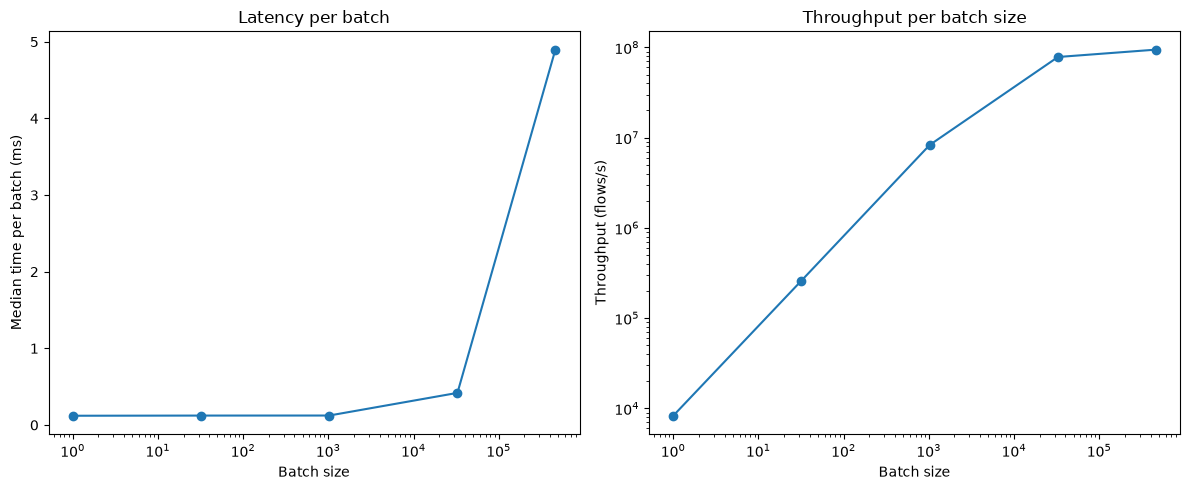

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(curva_batch["batch_size"], curva_batch["median_time_ms"], marker='o')
axes[0].set_xscale('log')
axes[0].set_xlabel("Batch size")
axes[0].set_ylabel("Median time per batch (ms)")
axes[0].set_title("Latency per batch")

axes[1].plot(curva_batch["batch_size"], curva_batch["throughput_flows_per_s"], marker='o')
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_xlabel("Batch size")
axes[1].set_ylabel("Throughput (flows/s)")
axes[1].set_title("Throughput per batch size")

plt.tight_layout()


### Equivalent network bandwidth

This only measures autoencoder inference on GPU with data already in GPU memory. It excludes feature
extraction (CICFlowMeter), packet capture and the CPU→GPU copy. It shows that the autoencoder is not the
bottleneck, not that the whole system sustains this bandwidth.

In [30]:
print(X_val['Fwd Packets Length Total'].describe())
print(X_val['Bwd Packets Length Total'].describe())

# kept in bytes for the computation; KB only for printing
byte_per_flusso = (X_val['Fwd Packets Length Total'] + X_val['Bwd Packets Length Total']).mean()
print(f"\nMean bytes per flow: {byte_per_flusso:.0f} ({byte_per_flusso/1024:.1f} KB)")

throughput_max = curva_batch["throughput_flows_per_s"].iloc[-1]
banda_implicita_bps = throughput_max * byte_per_flusso * 8
print(f"Equivalent bandwidth at {throughput_max:.0f} flows/s: {banda_implicita_bps/1e9:.1f} Gbps")
print("(AE inference only, data already in GPU memory: CICFlowMeter and CPU->GPU copy excluded)")


count      462,193.00
mean           659.29
std         19,865.60
min              0.00
25%             37.00
50%             74.00
75%            356.00
max     12,900,000.00
Name: Fwd Packets Length Total, dtype: float64
count      462,193.00
mean         6,327.29
std         81,700.04
min              0.00
25%             24.00
50%            182.00
75%          2,279.00
max     20,100,000.00
Name: Bwd Packets Length Total, dtype: float64

Mean bytes per flow: 6987 (6.8 KB)
Equivalent bandwidth at 94381481 flows/s: 5275.2 Gbps
(AE inference only, data already in GPU memory: CICFlowMeter and CPU->GPU copy excluded)


## 7. Autoencoder ensemble (raw and log-transformed features)

The second autoencoder sees features after a signed log, which compresses the heavy tails (bytes, packets,
durations) and keeps the `-1` sentinel of `Init Fwd/Bwd Win Bytes` distinct. Alone it is slightly worse, but it
catches different attacks (better on slow DoS and DDoS, worse on DoS Hulk). Each score is divided by its own
99th Benign percentile, then the two are averaged.

In [31]:
def log_con_segno(X):
    X = np.asarray(X, dtype=np.float64)
    return np.sign(X) * np.log1p(np.abs(X))   # -1 -> -0.69, 0 -> 0, 1e6 -> 13.8

scaler_log = StandardScaler().fit(log_con_segno(X_train_bening))
X_train_log_tensor = torch.tensor(scaler_log.transform(log_con_segno(X_train_bening)), dtype=torch.float32).to(device)
X_val_log_tensor = torch.tensor(scaler_log.transform(log_con_segno(X_val)), dtype=torch.float32).to(device)

torch.manual_seed(42)
model_log = Autoencoder().to(device)
for lr in [0.01, 0.001]:
    optimizer = torch.optim.Adam(model_log.parameters(), lr=lr)
    allena_fino_a_plateau(model_log, optimizer, X_train_log_tensor, criterion, log_ogni=200)

model_log.eval()
with torch.no_grad():
    errori_log = ((model_log(X_val_log_tensor) - X_val_log_tensor) ** 2).mean(dim=1).cpu().numpy()

# each score divided by its own 99th Benign percentile, so both models weigh the same
mask_benign_val = (y_val == "Benign").to_numpy()
norm_manuale = np.percentile(errori[mask_benign_val], 99)
norm_log = np.percentile(errori_log[mask_benign_val], 99)
ens = (errori / norm_manuale + errori_log / norm_log) / 2

epoch 0: loss=0.9088


epoch 200: loss=0.1019


epoch 400: loss=0.0824


epoch 600: loss=0.0758


epoch 800: loss=0.0721


epoch 1000: loss=0.0706


Plateau at epoch 1033 (mean of last 50: 0.0694, improvement 0.16%)
epoch 0: loss=0.0689


Plateau at epoch 110 (mean of last 50: 0.0683, improvement 0.19%)


In [32]:
# single autoencoder vs ensemble, XGBoost trained on all classes, 99th percentile threshold
for nome_clf, p in [("XGBoost default", preds_default), ("XGBoost weighted", preds)]:
    for nome_score, score in [("single", errori), ("ensemble", ens)]:
        soglia = np.percentile(score[mask_benign_val], 99)
        r = pipeline_ibrida(p, y_val_enc, y_val_reset, score, soglia)
        print(f"{nome_clf:16s} {nome_score:9s} recall {r['recall_solo_clf']:.4f} -> {r['recall_ibrido']:.4f} | "
              f"recovered {r['fn_recuperati']} | extra FP {r['fp_aggiunti']}")

XGBoost default  single    recall 0.9806 -> 0.9837 | recovered 209 | extra FP 3813
XGBoost default  ensemble  recall 0.9806 -> 0.9851 | recovered 304 | extra FP 3751
XGBoost weighted single    recall 0.9987 -> 0.9987 | recovered 3 | extra FP 3949
XGBoost weighted ensemble  recall 0.9987 -> 0.9987 | recovered 4 | extra FP 3878


## 8. Zero-day: one attack family left out of training

A binary XGBoost (Benign / attack) is retrained without one family at a time. The autoencoders are unchanged:
they never saw attacks, so for them every attack is a zero-day.

Key result: on the DoS family recall goes from 18% (XGBoost alone) to 75% with the autoencoder, at 1% extra
false positives. On the other families the autoencoder adds almost nothing: port scans, brute force and bots
are only visible across many flows, web attacks only in the request content. A per-flow autoencoder is a
safety net for attacks visible in a single flow.

In [33]:
famiglie = {
    "DoS": ["DDoS", "DoS Hulk", "DoS GoldenEye", "DoS slowloris", "DoS Slowhttptest"],
    "PortScan": ["PortScan"],
    "Bot": ["Bot"],
    "Brute force": ["FTP-Patator", "SSH-Patator"],
    "Web attack": ["Web Attack - Brute Force", "Web Attack - XSS", "Web Attack - Sql Injection"],
    "Infiltration": ["Infiltration"],
    "Heartbleed": ["Heartbleed"],
}

soglie_ens = {p: np.percentile(ens[mask_benign_val], p) for p in [99, 99.9]}
y_train_bin = (y_train != "Benign").astype(int).to_numpy()
righe, preds_zeroday, modelli_zeroday = [], {}, {}

for nome_fam, classi in famiglie.items():
    mask_train = (~y_train.isin(classi)).to_numpy()   # the family disappears from training
    clf = XGBClassifier(random_state=42, n_estimators=100, max_depth=6, device="cuda")
    clf.fit(X_train[mask_train], y_train_bin[mask_train])
    p = clf.predict(X_val)
    preds_zeroday[nome_fam] = p
    modelli_zeroday[nome_fam] = clf   # reused on the test set in section 10

    fam_val = y_val_reset.isin(classi).to_numpy()
    n_fam = fam_val.sum()
    rilevati_xgb = (p[fam_val] == 1).sum()
    riga = {"family": nome_fam, "cases in val": n_fam, "recall XGBoost": rilevati_xgb / n_fam}
    for perc, soglia in soglie_ens.items():
        salvati = ((p == 0) & fam_val & (ens > soglia)).sum()
        riga[f"recall pipeline {perc}°"] = (rilevati_xgb + salvati) / n_fam
        riga[f"FP AE {perc}°"] = ((p == 0) & mask_benign_val & (ens > soglia)).sum()
    righe.append(riga)

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
tabella_famiglie = pd.DataFrame(righe)
print(tabella_famiglie.to_string(index=False))
preds_nodos = preds_zeroday["DoS"]

      family  cases in val  recall XGBoost  recall pipeline 99°  FP AE 99°  recall pipeline 99.9°  FP AE 99.9°
         DoS         64314           0.180                0.749       3947                  0.470          393
    PortScan           391           0.174                0.176       3879                  0.174          395
         Bot           288           0.000                0.017       3880                  0.003          394
 Brute force          1829           0.001                0.002       3878                  0.001          393
  Web attack           429           0.583                0.583       3881                  0.583          394
Infiltration             7           0.000                0.143       3880                  0.143          394
  Heartbleed             2           0.000                1.000       3880                  1.000          393


**Reading the table**

- Heartbleed has 2 validation cases and Infiltration 7: "100%" means 2 of 2, "14.3%" means 1 of 7.
  These percentages are not reliable estimates; only DoS (64,314 cases) and, partly, the families with a few
  hundred cases matter.
- In-domain check (XGBoost trained on all classes): recall 98.06% → 98.51% on validation (single vs ensemble
  cell above). The same check on the test set is in section 10.

### Threshold as an operating setting

Precision, recall and F1 of the whole pipeline (XGBoost false positives included), normal scenario and DoS zero-day.
99.9th percentile = routine mode (almost no cost on known attacks); 99th = alert mode (maximum zero-day coverage).

In [34]:
for perc in [99, 99.9]:
    soglia = np.percentile(ens[mask_benign_val], perc)
    for nome, p in [("normal (default)", preds_default), ("zero-day without DoS", preds_nodos)]:
        r = pipeline_ibrida(p, y_val_enc, y_val_reset, ens, soglia)
        tp = ((p != 0) & ~mask_benign_val).sum() + r["fn_recuperati"]
        fp = ((p != 0) & mask_benign_val).sum() + r["fp_aggiunti"]
        prec, rec = tp / (tp + fp), r["recall_ibrido"]
        print(f"{perc}° {nome:20s} recall {rec:.4f} | precision {prec:.4f} | "
              f"F1 {2 * prec * rec / (prec + rec):.4f} | false alarms {fp}")

99° normal (default)     recall 0.9851 | precision 0.9270 | F1 0.9552 | false alarms 5220
99° zero-day without DoS recall 0.7578 | precision 0.9272 | F1 0.8340 | false alarms 3999
99.9° normal (default)     recall 0.9826 | precision 0.9733 | F1 0.9779 | false alarms 1816
99.9° zero-day without DoS recall 0.4909 | precision 0.9867 | F1 0.6556 | false alarms 445


### Alerts by score band

Autoencoder alerts split by score band. In the normal scenario the low bands are almost only false alarms;
during the zero-day every band fills with attacks and the alert volume jumps. The per-band alert count over time
is itself a signal: on a normal day only the top bands need review (~480 alerts instead of ~4,000: 440 + 41 flows above the 99.9th percentile vs 1,967 + 1,607 + 440 + 41 over the 99th).

In [35]:
percentili_fasce = [99, 99.5, 99.9, 99.99]
confini = [np.percentile(ens[mask_benign_val], p) for p in percentili_fasce] + [np.inf]
etichette_fasce = ["99-99.5", "99.5-99.9", "99.9-99.99", ">99.99"]

def tabella_rischio(preds_clf, nome_scenario):
    passati = preds_clf == 0          # the autoencoder only sees what XGBoost calls Benign
    righe = []
    for i, etichetta in enumerate(etichette_fasce):
        in_fascia = passati & (ens > confini[i]) & (ens <= confini[i + 1])
        attacchi = (in_fascia & ~mask_benign_val).sum()
        benigni = (in_fascia & mask_benign_val).sum()
        tot = attacchi + benigni
        righe.append({"band (Benign percentile)": etichetta, "alerts": tot, "true attacks": attacchi,
                      "false alarms": benigni, "precision": attacchi / tot if tot else float("nan")})
    print(f"=== {nome_scenario} ===")
    print(pd.DataFrame(righe).to_string(index=False))

tabella_rischio(preds_default, "normal (default XGBoost)")
tabella_rischio(preds_nodos, "zero-day (without DoS)")

=== normal (default XGBoost) ===
band (Benign percentile)  alerts  true attacks  false alarms  precision
                 99-99.5    1967            97          1870      0.049
               99.5-99.9    1607            73          1534      0.045
              99.9-99.99     440           131           309      0.298
                  >99.99      41             3            38      0.073
=== zero-day (without DoS) ===
band (Benign percentile)  alerts  true attacks  false alarms  precision
                 99-99.5    3854          1879          1975      0.488
               99.5-99.9   17650         16071          1579      0.911
              99.9-99.99   18964         18610           354      0.981
                  >99.99      64            25            39      0.391


## 9. Cross-dataset: does the pipeline transfer to another network?

Results from when these cells were run during the project:

| Test | Result |
|---|---|
| Trained on 2017, evaluated on CSE-CIC-IDS2018 | XGBoost ~0% on every family; AE with 2017 thresholds flags 37% of 2018 Benign, after recalibration it detects almost nothing |
| Within 2018 (train and test on 2018) | XGBoost: DoS 100%, Bot 99.9%, Brute force 100%: the data is learnable, the **transfer** fails |
| AE on 2017+2018 Benign, tested on CIC-DDoS2019 | Fewer false alarms than 2017 only (21.7% vs 33.7% at 99.9th) but no separation after recalibration |
| AE trained on 2018 Benign, 2018 attacks | LOIC-UDP 100%, Slowloris 76%, Web XSS 48%; Hulk 1.5% (82% of 2018 Hulk flows are empty, like 16% of 2018 Benign) |

Why it does not transfer: normal traffic differs between networks (median `Init Fwd Win Bytes` 58 vs 8,192),
shortcut learning (55% of the 2017 XGBoost importance is on `Bwd Packet Length Std`, i.e. on that network's
server responses), empty attack flows in 2018.

Conclusion: the autoencoder needs a **per-network baseline**: train it on the normal traffic of the network where
it runs (no labelled attacks needed), collected when no attack is in progress, and retrain it periodically.

The cells below reproduce these experiments. They are **off** in this run (`ESEGUI_CROSS_DATASET = False`)
because they download CSE-CIC-IDS2018 and CIC-DDoS2019 (~630 MB) and train several models. The first cell
always runs: it defines functions used in section 10.

In [36]:
ESEGUI_CROSS_DATASET = False

import gc
import pyarrow.parquet as pq

def carica_parquet(percorso, solo_benign=None):
    """Reads a CIC parquet, keeps the 77 features used for 2017 and applies the same cleaning."""
    d = pd.read_parquet(percorso)
    if solo_benign is True:
        d = d[d["Label"] == "Benign"]
    elif solo_benign is False:
        d = d[d["Label"] != "Benign"]
    X = d[X_train.columns].astype(np.float32)
    lab = d["Label"].to_numpy()
    del d
    valide = np.isfinite(X.to_numpy()).all(axis=1) & ~(X[dirty_colm] < 0).any(axis=1).to_numpy()
    return X[valide].reset_index(drop=True), lab[valide]

# label names differ across CIC datasets: map them to the same families
def famiglia_cic(label):
    l = str(label).lower()
    if l == "benign": return "Benign"
    if "dos" in l: return "DoS"
    if "bot" in l: return "Bot"
    if "ftp" in l or "ssh" in l: return "Brute force"
    if "web" in l or "xss" in l or "sql" in l: return "Web attack"
    if "infil" in l: return "Infiltration"
    return "Other: " + str(label)

# batched, so millions of rows do not have to fit in GPU memory at once
def errori_modello(trasforma, sc, m, X_df, batch=200_000):
    X = trasforma(X_df) if trasforma else X_df.to_numpy()
    X = sc.transform(X).astype(np.float32)
    out = np.empty(len(X), dtype=np.float32)
    m.eval()
    with torch.no_grad():
        for i in range(0, len(X), batch):
            a = torch.from_numpy(X[i:i + batch]).to(device)
            out[i:i + batch] = ((m(a) - a) ** 2).mean(dim=1).cpu().numpy()
    return out

# ensemble score: mean of the normalised errors
def punteggio(modelli, X_df, norm):
    return sum(errori_modello(t, s, m, X_df) / n for (t, s, m), n in zip(modelli, norm)) / len(modelli)

def allena_ensemble(X_benign_df, seed=42):
    modelli = []
    for trasforma in [None, log_con_segno]:
        Xtr = trasforma(X_benign_df) if trasforma else X_benign_df.to_numpy()
        sc = StandardScaler().fit(Xtr)
        Xt = torch.tensor(sc.transform(Xtr), dtype=torch.float32).to(device)
        torch.manual_seed(seed)
        m = Autoencoder().to(device)
        for lr in [0.01, 0.001]:
            opt = torch.optim.Adam(m.parameters(), lr=lr)
            allena_fino_a_plateau(m, opt, Xt, criterion, log_ogni=500)
        m.eval()
        del Xt; torch.cuda.empty_cache()
        modelli.append((trasforma, sc, m))
    return modelli

# the 2017 ensemble trained above, in the same (transform, scaler, model) format
modelli17 = [(None, StandardScaler().fit(X_train_bening.to_numpy()), model), (log_con_segno, scaler_log, model_log)]
norm17 = [norm_manuale, norm_log]

In [37]:
# 2017 -> 2018: XGBoost and autoencoders trained on 2017, evaluated on 2018 without retraining
if ESEGUI_CROSS_DATASET:
    path18 = kagglehub.dataset_download("dhoogla/csecicids2018")
    file18 = sorted(f for f in os.listdir(path18) if f.endswith(".parquet"))

    xgb_full = XGBClassifier(random_state=42, n_estimators=100, max_depth=6, device="cuda")
    xgb_full.fit(X_train, y_train_bin)
    soglie17 = {p: np.percentile(ens[mask_benign_val], p) for p in [99, 99.9]}

    rng = np.random.default_rng(42)
    parti = {"fam": [], "pred": [], "score": [], "calib": []}
    for nome in file18:
        X18, lab18 = carica_parquet(os.path.join(path18, nome))
        fam18 = pd.Series(lab18).map({u: famiglia_cic(u) for u in pd.unique(lab18)}).to_numpy()
        parti["fam"].append(fam18)
        parti["pred"].append(xgb_full.predict(X18))
        parti["score"].append(punteggio(modelli17, X18, norm17))
        # 20% of 2018 Benign held out to recalibrate the thresholds, excluded from evaluation
        parti["calib"].append((fam18 == "Benign") & (rng.random(len(fam18)) < 0.2))
        del X18; gc.collect()
    fam18, pred18, score18, calib18 = (np.concatenate(parti[k]) for k in ["fam", "pred", "score", "calib"])
    soglie18 = {p: np.percentile(score18[(fam18 == "Benign") & calib18], p) for p in [99, 99.9]}

    righe = []
    for g in [f for f in pd.unique(fam18) if f != "Benign"] + ["Benign"]:
        m = (fam18 == g) & ~calib18
        r = {"group": g, "cases": int(m.sum()), "XGB": (pred18[m] == 1).mean()}
        for tag, soglie in [("2017 threshold", soglie17), ("recalibrated", soglie18)]:
            r[f"99° {tag}"] = ((pred18[m] == 1) | (score18[m] > soglie[99])).mean()
        righe.append(r)
    print("Benign row = false alarm rate")
    print(pd.DataFrame(righe).to_string(index=False))

In [38]:
# Within 2018: autoencoders trained on 2018 Benign, evaluated on 2018 attacks
if ESEGUI_CROSS_DATASET:
    N = len(X_train_bening)
    # subsample 2018 Benign (5,329,008 rows) to about 0.75x the 2017 Benign training size
    frazione = min(1.0, 0.75 * N / 5_329_008)
    rng = np.random.default_rng(1)
    parti = []
    for nome in file18:
        Xb, _ = carica_parquet(os.path.join(path18, nome), solo_benign=True)
        parti.append(Xb[rng.random(len(Xb)) < frazione])
        del Xb; gc.collect()
    benign18 = pd.concat(parti, ignore_index=True); del parti
    benign18_train = benign18.sample(frac=0.7, random_state=42)
    benign18_hold = benign18.drop(benign18_train.index)
    del benign18; gc.collect()

    modelli18 = allena_ensemble(benign18_train)
    norm18 = [np.percentile(errori_modello(t, s, m, benign18_hold), 99) for (t, s, m) in modelli18]
    s_hold18 = punteggio(modelli18, benign18_hold, norm18)

    righe = []
    for nome in file18:
        Xa, laba = carica_parquet(os.path.join(path18, nome), solo_benign=False)
        if len(Xa) == 0:
            continue
        s = punteggio(modelli18, Xa, norm18)
        for e in pd.unique(laba):
            m = laba == e
            righe.append({"attack": e, "cases": int(m.sum()),
                          "detected 99°": int((s[m] > np.percentile(s_hold18, 99)).sum()),
                          "detected 99.9°": int((s[m] > np.percentile(s_hold18, 99.9)).sum())})
        del Xa; gc.collect()
    tab_ae18 = pd.DataFrame(righe).groupby("attack", as_index=False).sum()
    tab_ae18["recall 99°"] = tab_ae18["detected 99°"] / tab_ae18["cases"]
    tab_ae18["recall 99.9°"] = tab_ae18["detected 99.9°"] / tab_ae18["cases"]
    print(tab_ae18.sort_values("cases", ascending=False).to_string(index=False))

In [39]:
# Benign from more networks: A = 2017 only, B = 2017 + 2018 (same row count), tested on CIC-DDoS2019
if ESEGUI_CROSS_DATASET:
    path19 = kagglehub.dataset_download("dhoogla/cicddos2019")
    file19 = sorted(f for f in os.listdir(path19) if f.endswith(".parquet"))
    blocchi = [carica_parquet(os.path.join(path19, f)) for f in file19]
    X19 = pd.concat([b[0] for b in blocchi], ignore_index=True)
    lab19 = np.concatenate([b[1] for b in blocchi])
    del blocchi; gc.collect()
    ben19 = np.array([str(l).lower() == "benign" for l in lab19])
    calib19 = ben19 & (np.random.default_rng(7).random(len(lab19)) < 0.2)

    benign17_val = X_val[mask_benign_val].reset_index(drop=True)
    k = min(len(benign17_val), len(benign18_hold))
    configurazioni = {
        "A: 2017 only": (X_train_bening, benign17_val),
        "B: 2017 + 2018": (
            pd.concat([X_train_bening.sample(n=N // 2, random_state=1),
                       benign18_train.sample(n=N // 2, random_state=1)], ignore_index=True),
            pd.concat([benign17_val.sample(n=k, random_state=1),
                       benign18_hold.sample(n=k, random_state=1)], ignore_index=True),
        ),
    }

    righe = []
    for nome, (X_tr, X_hold) in configurazioni.items():
        modelli = allena_ensemble(X_tr)
        norm = [np.percentile(errori_modello(t, s, m, X_hold), 99) for (t, s, m) in modelli]
        s_hold = punteggio(modelli, X_hold, norm)
        s19 = punteggio(modelli, X19, norm)
        r = {"configuration": nome}
        for p in [99, 99.9]:
            soglia_orig, soglia_19 = np.percentile(s_hold, p), np.percentile(s19[calib19], p)
            r[f"FPR original threshold {p}°"] = (s19[ben19 & ~calib19] > soglia_orig).mean()
            r[f"FPR recalibrated {p}°"] = (s19[ben19 & ~calib19] > soglia_19).mean()
            r[f"recall recalibrated {p}°"] = (s19[~ben19] > soglia_19).mean()
        righe.append(r)
        del modelli; gc.collect(); torch.cuda.empty_cache()
    print(pd.DataFrame(righe).set_index("configuration").T.to_string())

## 10. Final check on the test set

Same models, thresholds computed on validation, test set used once.

In the table below, `false alarms` is the total (XGBoost false alarms + those added by the autoencoder); the extra ones alone are ~1% of Benign at the 99th percentile (3,944 in the README).

In [40]:
y_test_enc = le.transform(y_test)
y_test_reset = y_test.reset_index(drop=True)
mask_benign_test = (y_test == "Benign").to_numpy()

preds_default_test = xgb_model_default.predict(X_test)
preds_nodos_test = modelli_zeroday["DoS"].predict(X_test)
ens_test = punteggio(modelli17, X_test, norm17)   # same autoencoders and normalisation as validation


def riepilogo(preds_clf, y_enc, y_lab, score, soglia, mask_benign):
    """Precision/recall/F1 of the whole pipeline (XGBoost false alarms + those added by the AE)."""
    r = pipeline_ibrida(preds_clf, y_enc, y_lab, score, soglia)
    tp = ((preds_clf != 0) & ~mask_benign).sum() + r["fn_recuperati"]
    fp = ((preds_clf != 0) & mask_benign).sum() + r["fp_aggiunti"]
    prec, rec = tp / (tp + fp), r["recall_ibrido"]
    return {"recall XGB": r["recall_solo_clf"], "recall pipeline": rec, "precision": prec,
            "F1": 2 * prec * rec / (prec + rec), "false alarms": int(fp), "total FPR": r["fpr_ibrido"]}


righe = []
for perc, soglia in soglie_ens.items():          # validation thresholds, not recomputed
    for nome, p in [("normal (default)", preds_default_test), ("zero-day without DoS", preds_nodos_test)]:
        righe.append({"threshold": f"{perc}°", "scenario": nome,
                      **riepilogo(p, y_test_enc, y_test_reset, ens_test, soglia, mask_benign_test)})
print("=== TEST SET: whole pipeline ===")
print(pd.DataFrame(righe).to_string(index=False))
# if the validation thresholds generalise, the AE alone flags ~1% and ~0.1% of test Benign
print(f"\nAutoencoder-only FPR on test Benign: "
      + ", ".join(f"{p}° -> {(ens_test[mask_benign_test] > s).mean():.2%}" for p, s in soglie_ens.items())
      + "  (expected ~1% and ~0.1% if the thresholds generalise)")


=== TEST SET: whole pipeline ===
threshold             scenario  recall XGB  recall pipeline  precision    F1  false alarms  total FPR
      99°     normal (default)       0.979            0.984      0.927 0.955          5176      0.013
      99° zero-day without DoS       0.215            0.756      0.927 0.833          3988      0.010
    99.9°     normal (default)       0.979            0.981      0.974 0.978          1767      0.004
    99.9° zero-day without DoS       0.215            0.495      0.987 0.659           437      0.001

Autoencoder-only FPR on test Benign: 99° -> 1.00%, 99.9° -> 0.10%  (expected ~1% and ~0.1% if the thresholds generalise)


In [41]:
# zero-day per family on the test set, same logic as the validation table
righe = []
for nome_fam, classi in famiglie.items():
    p = modelli_zeroday[nome_fam].predict(X_test)
    fam_test = y_test_reset.isin(classi).to_numpy()
    riga = {"family": nome_fam, "cases in test": int(fam_test.sum()),
            "recall XGBoost": (p[fam_test] == 1).mean()}
    for perc, soglia in soglie_ens.items():
        riga[f"recall pipeline {perc}°"] = ((p[fam_test] == 1) | (ens_test[fam_test] > soglia)).mean()
        riga[f"FP AE {perc}°"] = int(((p == 0) & mask_benign_test & (ens_test > soglia)).sum())
    righe.append(riga)
print("=== TEST SET: zero-day per family ===")
print(pd.DataFrame(righe).to_string(index=False))


=== TEST SET: zero-day per family ===
      family  cases in test  recall XGBoost  recall pipeline 99°  FP AE 99°  recall pipeline 99.9°  FP AE 99.9°
         DoS          64317           0.181                0.747       3944                  0.474          393
    PortScan            391           0.128                0.128       3886                  0.128          394
         Bot            287           0.000                0.038       3885                  0.017          394
 Brute force           1829           0.003                0.004       3886                  0.003          394
  Web attack            428           0.617                0.617       3886                  0.617          394
Infiltration              7           0.000                0.429       3887                  0.286          394
  Heartbleed              1           0.000                1.000       3885                  1.000          394


### Robustness: 5 seeds

Autoencoder results vary between trainings (weight initialisation, dropout). The ensemble is retrained with
5 seeds, each time with normalisation and thresholds from validation, measured on test.

In [42]:
seeds = [0, 1, 2, 3, 4]
dos_test = y_test_reset.isin(famiglie["DoS"]).to_numpy()
benign_val_df = X_val[mask_benign_val]
righe = []

for seed in seeds:
    print(f"\n=== seed {seed} ===")
    modelli = allena_ensemble(X_train_bening, seed=seed)
    norm = [np.percentile(errori_modello(t, s, m, benign_val_df), 99) for (t, s, m) in modelli]
    s_val = punteggio(modelli, X_val, norm)
    s_test = punteggio(modelli, X_test, norm)

    riga = {"seed": seed}
    for perc in [99, 99.9]:
        soglia = np.percentile(s_val[mask_benign_val], perc)          # threshold from validation
        riga[f"recall DoS zero-day {perc}°"] = ((preds_nodos_test[dos_test] == 1) | (s_test[dos_test] > soglia)).mean()
        riga[f"recall normal {perc}°"] = riepilogo(preds_default_test, y_test_enc, y_test_reset,
                                                    s_test, soglia, mask_benign_test)["recall pipeline"]
        riga[f"FPR AE {perc}°"] = (s_test[mask_benign_test] > soglia).mean()
    righe.append(riga)
    del modelli; gc.collect(); torch.cuda.empty_cache()

tab_seed = pd.DataFrame(righe).set_index("seed")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
print(tab_seed.to_string())
print("\nMean ± standard deviation over 5 seeds (test set):")
for col in tab_seed.columns:
    print(f"  {col:28s} {tab_seed[col].mean():.2%} ± {tab_seed[col].std():.2%}")



=== seed 0 ===


epoch 0: loss=0.9091


Plateau at epoch 472 (mean of last 50: 0.1163, improvement -0.12%)
epoch 0: loss=0.1076


Plateau at epoch 147 (mean of last 50: 0.1073, improvement -0.33%)


epoch 0: loss=0.9098


...

epoch 500: loss=0.0829


epoch 1000: loss=0.0721


Plateau at epoch 1175 (mean of last 50: 0.0711, improvement 0.16%)
epoch 0: loss=0.0711


Plateau at epoch 133 (mean of last 50: 0.0697, improvement 0.18%)


      recall DoS zero-day 99°  recall normal 99°  FPR AE 99°  recall DoS zero-day 99.9°  recall normal 99.9°  FPR AE 99.9°
seed                                                                                                                      
0                      0.7463             0.9842      0.0099                     0.4420               0.9807        0.0010
1                      0.7339             0.9842      0.0100                     0.4290               0.9806        0.0010
2                      0.7403             0.9844      0.0098                     0.4202               0.9803        0.0009
3                      0.7448             0.9841      0.0100                     0.4587               0.9803        0.0010
4                      0.7399             0.9843      0.0099                     0.4522               0.9805        0.0010

Mean ± standard deviation over 5 seeds (test set):
  recall DoS zero-day 99°      74.10% ± 0.49%
  recall normal 99°            98.42% ± 0

## 11. Conclusion and limits

- **What the second stage does.** When XGBoost has seen every class, the autoencoder moves test recall only from 97.9% to 98.4%. When one family is missing from training (DoS), DoS recall goes from 18.1% to 74.7% at the 99th percentile, at a cost of ~1% extra false alarms. It makes an unseen attack visible; it does not classify it, and legitimate but unusual traffic raises an alert too.
- **Random split.** Flows of the same attack session end up in both train and test, so the in-domain numbers are optimistic.
- **Zero-day estimates.** Only DoS (64k cases) and, partly, the families with a few hundred cases are reliable. Infiltration (7 cases) and Heartbleed (1) are not estimates.
- **No transfer across networks.** Section 9 shows that models trained on CIC-IDS2017 fail on other datasets; it is switched off by default (`ESEGUI_CROSS_DATASET = False`).
- **Flow features only.** No packet content and no sequence of flows: port scans, brute force and bots look normal one flow at a time.
- **Hardware.** XGBoost uses `device="cuda"`: a CUDA GPU is needed to run the notebook.